# Auclert's redistribution channels in the canonical HANK

Auclert (2019) shows that, on impact, aggregate consumption responds to the real rate and the price level through a few cross-sectional moments (his equation 19 and Corollary 2):

$$\frac{dC}{C}=(\mathcal{M}+\gamma\mathcal{E}_Y)\frac{dY}{Y}-\mathcal{E}_P\frac{dP}{P}+\left(\mathcal{E}_R-\tfrac{1}{\sigma}S\right)\frac{dR}{R}$$

This notebook computes these moments in the canonical HANK model of the lecture and compares them with his estimates (Table 4).
The model is annual, and Auclert measures everything at an annual rate, so the numbers are comparable.
Our $\sigma$ is the CRRA coefficient, so the EIS is $\frac{1}{\sigma}$.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import HANKModel

## Settings

In [2]:
# Auclert (2019), Table 4: SHIW, PSID, CE
Auclert = {
    'E_R':    [-0.10,-0.12,-0.23],
    'E_R_NR': [ 0.28, 0.00,-0.09],
    'S':      [ 0.55, 0.90, 0.64],
    'E_P':    [-0.07, 0.02,-0.09],
    'E_P_NR': [ 0.05,-0.01,-0.45],
    'E_Y':    [-0.05,-0.06,-0.13],
    'M':      [ 0.55, 0.08, 0.46],
}
surveys = ['SHIW','PSID','CE']

# Auclert's experiment: the real rate falls by 1 percent, the price level rises by 1 percent
dR_over_R = -0.01
dP_over_P = 0.01

N_bins = 10

## 1. Model and steady state

The canonical HANK model of the course (the solution of the 09-10 HANK exercise, `model_type='canonical'`), with three changes:

- **Borrowing:** households can borrow down to `par.a_min` $=-0.25$, about a third of annual labor income. A negative $a$ is a short position in the fund: borrowers pay the fund's return.
- **Long-term bonds:** government bonds pay coupons $1,\\delta,\\delta^2,\\dots$, with a duration of `par.duration_B` $=5$ years. Only the coupon matures each year; the rest is revalued when rates move.
- **Two rate inputs:** the household block takes the rate in the Euler equation, `r`, separately from the return in the budget, `ra`. This gives the substitution Jacobian $\\boldsymbol{M}^{sub}$ directly (section 3).

The rest is the exercise model: markups, so households hold a fund of stocks $p$ and bonds $B$, with $A=5$ and $B=1$ times annual output; two discount factors, $\\beta_L=0.82$ and $\\beta_H$, redrawn with probability 4 percent a year; $\\sigma=1$, so the EIS is 1; and $\\zeta=0$.
Bonds are nominal.

In [3]:
model = HANKModel.HANKModelClass(name='canonical',par={'nominal_bonds':True})
model.find_ss(do_print=True)
model._compute_jac_hh()

par = model.par
ss = model.ss

steady state found in 4.8 secs
 beta_L =   0.8200, beta_H =   1.0002
 mu     =   1.1143
 tau    =   0.2200
 p      =   4.0000
Discrepancy in A =   0.00000000
Discrepancy in Y =   0.00000234


## 2. MPCs and exposures

A household's state is $(z_{i0},\beta_{i0},a_{i,-1})$, with weights `ss.D`.

- **MPC**: out of cash on hand $m=(1+r)a_{i,-1}+Z z_{i0}$, by finite differences of the consumption policy on the grid.
- **URE** (unhedged interest rate exposure): what the household must reinvest at the new rate, $URE_i=a_{i0}-\frac{p}{A}a_{i,-1}$. Bonds mature every period, stocks already held are hedged.
- **NNP** (net nominal position): the bonds due at $t=0$, $NNP_i=(1+r_{ss})\frac{B}{A}a_{i,-1}$, if bonds are nominal.
- **Income**: after-tax labor income plus dividends, $Y_i=Z_{ss}z_{i0}+\frac{d}{A}a_{i,-1}$.

Caveat: with one fund and no borrowing, everybody has $NNP_i\ge0$, and both exposures are close to proportional to wealth.
In the data, adjustable-rate borrowers have negative URE and fixed-rate mortgages hedge part of it.

In [4]:
MPC = np.zeros_like(ss.c)
MPC[...,:-1] = (ss.c[...,1:]-ss.c[...,:-1])/((1+ss.ra)*np.diff(par.a_grid))
MPC[...,-1] = MPC[...,-2]

a_lag = np.broadcast_to(par.a_grid[None,None,:],ss.c.shape)
URE = ss.a - (ss.p+par.delta_B*ss.B)/ss.A*a_lag
NNP = (1+ss.r)*ss.B/ss.A*a_lag
income = ss.Z*par.z_grid[None,:,None] + ss.d/ss.A*a_lag

C = np.sum(ss.D*ss.c)
print(f'average MPC          = {np.sum(ss.D*MPC):.3f}')
print(f'share borrowing      = {np.sum(ss.D*(a_lag<0)):.3f}')
print(f'share constrained    = {np.sum(ss.D*(ss.a<=par.a_min+1e-8)):.3f}')
print(f'E[URE] = {np.sum(ss.D*URE):.4f}, (1-delta)B = {(1-par.delta_B)*ss.B:.4f}')
print(f'E[NNP] = {np.sum(ss.D*NNP):.4f}, (1+r)B = {(1+ss.r)*ss.B:.4f}')

average MPC          = 0.465
share borrowing      = 0.466
share constrained    = 0.429
E[URE] = 0.1840, (1-delta)B = 0.1840
E[NNP] = 1.0200, (1+r)B = 1.0200


## 3. Check with the Jacobians

The household block has two rate inputs: `ra` is the return $r^p_t$ in the budget, and `r` is the rate $r_t$ in the Euler equation.
So `jac_hh[('C_hh','r')]` is the substitution Jacobian $\boldsymbol{M}^{sub}$, and part 1's $\boldsymbol{M}^r$ is `J_ra@Lag + M_sub`.

The first entries of these Jacobians are cross-sectional moments (see `Auclert-note.md`):

- $\partial C_0/\partial Z_0=\mathbb{E}[z_{i0}MPC_i]$
- $\partial C_0/\partial r^p_0=\mathbb{E}[MPC_i\,a_{i,-1}]$, the surprise return at $t=0$
- $\partial C_0/\partial r^p_1=\frac{1}{1+r_{ss}}\mathbb{E}[MPC_i\,a_{i0}]$, a known return next year (Fact 1)
- $M^{sub}_{0,0}=-\frac{1}{\sigma}\frac{1}{1+r_{ss}}\mathbb{E}[(1-MPC_i)c_{i0}]$, substitution (Fact 2, Auclert's Theorem 2)
- $M^r_{0,0}$, the sum of the last two

In [5]:
J_Z = model.jac_hh[('C_hh','Z')]
J_ra = model.jac_hh[('C_hh','ra')]
J_chi = model.jac_hh[('C_hh','chi')]
M_sub = model.jac_hh[('C_hh','r')]
Lag = np.eye(par.T,k=-1)
M_r = J_ra@Lag + M_sub

interior = ss.a > par.a_min+1e-8
income_effect = np.sum(ss.D*MPC*ss.a*interior)/(1+ss.r)
substitution = -np.sum(ss.D*(1-MPC)*ss.c)/par.sigma/(1+ss.r)

checks = pd.DataFrame({
    'Jacobian': [J_chi[0,0],J_Z[0,0],J_ra[0,0],J_ra[0,1],M_sub[0,0],M_r[0,0]],
    'formula': [
        np.sum(ss.D*MPC),
        np.sum(ss.D*par.z_grid[None,:,None]*MPC),
        np.sum(ss.D*MPC*a_lag),
        income_effect,
        substitution,
        income_effect+substitution,
    ]},
    index=['dC_0/dchi_0','dC_0/dZ_0','dC_0/dr^p_0','dC_0/dr^p_1','M^sub_00','M^r_00'])
checks['relative gap'] = checks['Jacobian']/checks['formula']-1
checks.round(4)

,Jacobian,formula,relative gap
dC_0/dchi_0,0.4651,0.4647,0.0008
dC_0/dZ_0,0.4576,0.4572,0.0007
dC_0/dr^p_0,0.0436,0.0434,0.0056
dC_0/dr^p_1,0.1325,0.1323,0.0015
M^sub_00,-0.4540,-0.4544,-0.0008
M^r_00,-0.3215,-0.3221,-0.0017


The small gaps come from the finite-difference MPC on the grid, which is least precise near the borrowing constraint.

## 4. Auclert's seven moments

His Table 1 definitions, all divided by average consumption:

- $\mathcal{E}_R=\text{cov}(MPC_i,URE_i)/C$ and, without the rebate, $\mathcal{E}_R^{NR}=\mathbb{E}[MPC_i\,URE_i]/C$
- $S=\mathbb{E}[(1-MPC_i)c_i]/C$, the Hicksian scaling factor
- $\mathcal{E}_P=\text{cov}(MPC_i,NNP_i)/C$ and $\mathcal{E}_P^{NR}=\mathbb{E}[MPC_i\,NNP_i]/C$
- $\mathcal{E}_Y=\text{cov}(MPC_i,Y_i)/C$ and $\mathcal{M}=\mathbb{E}[MPC_i\,Y_i]/C$

In the model the government holds the other side of all bonds and rebates lump-sum, so the covariances ($\mathcal{E}_R$, $\mathcal{E}_P$) are the relevant ones.

In [6]:
E_MPC = np.sum(ss.D*MPC)
moments = {
    'E_R':    (np.sum(ss.D*MPC*URE)-E_MPC*np.sum(ss.D*URE))/C,
    'E_R_NR': np.sum(ss.D*MPC*URE)/C,
    'S':      np.sum(ss.D*(1-MPC)*ss.c)/C,
    'E_P':    (np.sum(ss.D*MPC*NNP)-E_MPC*np.sum(ss.D*NNP))/C,
    'E_P_NR': np.sum(ss.D*MPC*NNP)/C,
    'E_Y':    (np.sum(ss.D*MPC*income)-E_MPC*np.sum(ss.D*income))/C,
    'M':      np.sum(ss.D*MPC*income)/C,
}

table = pd.DataFrame(Auclert,index=surveys).T
table.insert(0,'Model',pd.Series(moments))
table.loc['-E_R/S'] = -table.loc['E_R']/table.loc['S']
table.round(2)

,Model,SHIW,PSID,CE
E_R,-0.12,-0.10,-0.12,-0.23
E_R_NR,-0.02,0.28,0.00,-0.09
S,0.58,0.55,0.90,0.64
E_P,-0.58,-0.07,0.02,-0.09
E_P_NR,0.01,0.05,-0.01,-0.45
E_Y,-0.05,-0.05,-0.06,-0.13
M,0.40,0.55,0.08,0.46
-E_R/S,0.21,0.18,0.13,0.36


In [7]:
print(f'EIS in the model: 1/sigma = {1/par.sigma:.2f}')
print(f'-E_R/S in the model: {-moments["E_R"]/moments["S"]:.2f}')

EIS in the model: 1/sigma = 1.00
-E_R/S in the model: 0.21


Auclert's rule of thumb: compare $-\mathcal{E}_R/S$ with the EIS.
If they are of the same size, redistribution through interest rate exposure matters as much as intertemporal substitution.

## 5. Figures

### iMPCs by source of income

First column of the Jacobian of a transfer at $t=0$, per unit of aggregate income, for three ways of splitting it across households.

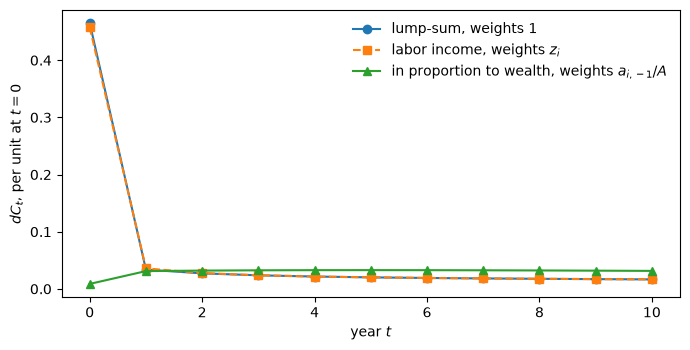

In [8]:
horizon = np.arange(11)

fig, ax = plt.subplots(figsize=(7,3.6))
ax.plot(horizon,J_chi[:11,0],'o-',label='lump-sum, weights $1$')
ax.plot(horizon,J_Z[:11,0],'s--',label='labor income, weights $z_i$')
ax.plot(horizon,J_ra[:11,0]/ss.A,'^-',label='in proportion to wealth, weights $a_{i,-1}/A$')
ax.set(xlabel='year $t$',ylabel='$dC_t$, per unit at $t=0$')
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig('figs/iMPC_by_source.pdf')

### MPCs by exposure

As in Auclert's Figure 2: the average MPC within each decile of the exposure.
Productivity takes only seven values, so the last panel shows the MPC by productivity state, pooling the two discount factors.

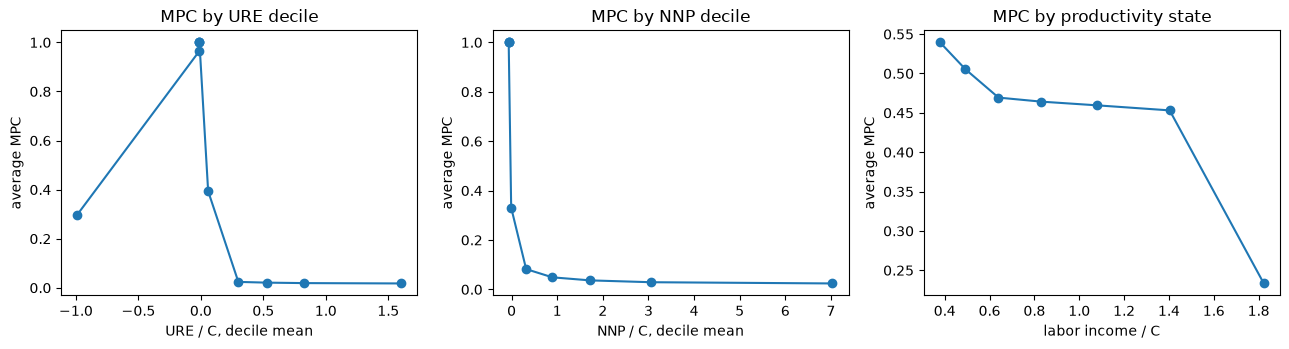

In [9]:
fig, axes = plt.subplots(1,3,figsize=(13,3.6))

for ax, exposure, title in zip(axes[:2],[URE,NNP],['URE','NNP']):

    order = np.argsort(exposure.ravel(),kind='stable')
    weights = ss.D.ravel()[order]
    bin_index = np.minimum((np.cumsum(weights)-weights/2)*N_bins,N_bins-1).astype(int)

    mean_exposure = np.full(N_bins,np.nan)
    mean_MPC = np.full(N_bins,np.nan)
    for i_bin in range(N_bins):
        in_bin = bin_index == i_bin
        if not in_bin.any(): continue
        mean_exposure[i_bin] = np.sum(weights[in_bin]*exposure.ravel()[order][in_bin])/np.sum(weights[in_bin])
        mean_MPC[i_bin] = np.sum(weights[in_bin]*MPC.ravel()[order][in_bin])/np.sum(weights[in_bin])

    filled = ~np.isnan(mean_MPC)
    ax.plot(mean_exposure[filled]/C,mean_MPC[filled],'o-')
    ax.set(xlabel=f'{title} / C, decile mean',ylabel='average MPC',title=f'MPC by {title} decile')

D_by_z = np.sum(ss.D,axis=(0,2)).reshape(par.Nbeta,par.Nz_e).sum(axis=0)
MPC_by_z = np.sum(ss.D*MPC,axis=(0,2)).reshape(par.Nbeta,par.Nz_e).sum(axis=0)/D_by_z
axes[2].plot(ss.Z*par.z_grid[:par.Nz_e]/C,MPC_by_z,'o-')
axes[2].set(xlabel='labor income / C',ylabel='average MPC',title='MPC by productivity state')

fig.tight_layout()
fig.savefig('figs/MPC_by_exposure.pdf')

### Auclert's experiment

The impact response of consumption to $dR/R=-1\%$ and $dP/P=+1\%$, from Corollary 2, channel by channel:

- Fisher: $-\mathcal{E}_P\,\frac{dP}{P}$
- interest rate exposure: $\mathcal{E}_R\,\frac{dR}{R}$
- substitution: $-\frac{1}{\sigma}S\,\frac{dR}{R}$

All columns use the model's EIS, $\frac{1}{\sigma}$, so only the measured moments differ.

In [10]:
channels = pd.DataFrame({
    'Fisher': -table.loc['E_P']*dP_over_P,
    'interest rate exposure': table.loc['E_R']*dR_over_R,
    'substitution': -table.loc['S']/par.sigma*dR_over_R,
}).T*100
channels.loc['total'] = channels.sum()
channels.round(3)

,Model,SHIW,PSID,CE
Fisher,0.581,0.07,-0.02,0.09
interest rate exposure,0.124,0.10,0.12,0.23
substitution,0.579,0.55,0.90,0.64
total,1.285,0.72,1.00,0.96


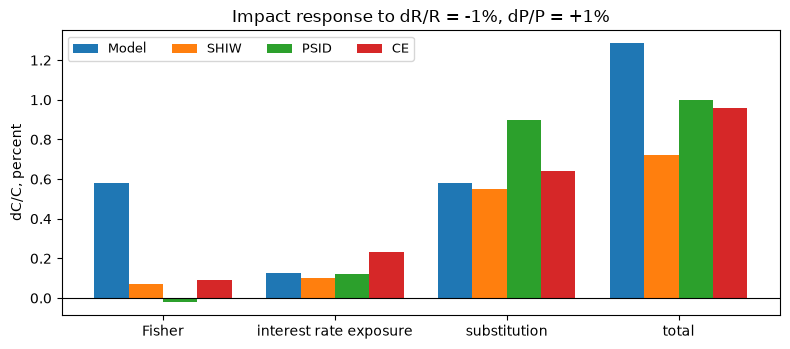

In [11]:
fig, ax = plt.subplots(figsize=(8,3.6))

width = 0.2
x = np.arange(len(channels.index))
for i_column, column in enumerate(channels.columns):
    ax.bar(x+(i_column-1.5)*width,channels[column],width,label=column)

ax.axhline(0,color='black',lw=0.8)
ax.set_xticks(x,channels.index)
ax.set(ylabel='dC/C, percent',title='Impact response to dR/R = -1%, dP/P = +1%')
ax.legend(ncol=4,fontsize=9)

fig.tight_layout()
fig.savefig('figs/Auclert_channels.pdf')

## 6. Takeaways

TAKEAWAYS